# Exploración P3 - Perfil de uso de estaciones MiBici

**Sergio Alejandro Canto Arizpe**

El objetivo de este notebook es explorar las características utilizadas en P3 para identificar estaciones de MiBici con patrones de uso similares. La exploración se realiza sobre el periodo de entrenamiento y utiliza las funciones reutilizables implementadas en los módulos del proyecto, manteniendo la lógica de procesamiento y modelado fuera del notebook.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJ_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJ_ROOT))

from mibici import config
from mibici.features import perfil_uso_estacion
from mibici.modeling.train_p3 import listar_parquet_entrenamiento

2026-10-18 14:46:25.274 | INFO     | mibici.config:<module>:12 - PROJ_ROOT path is: /home/sergiocanto/TC5061-Proyecto-Equipo06
/home/sergiocanto/TC5061-Proyecto-Equipo06/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Datos utilizados

Para P3 se utilizan exclusivamente los datos correspondientes al periodo de entrenamiento. Los archivos mensuales posteriores al inicio de validación se excluyen para mantener la separación temporal establecida en el proyecto. La nomenclatura de estaciones proporciona la capacidad y la identificación de las estaciones utilizadas para construir el perfil.

In [2]:
rutas_train = listar_parquet_entrenamiento()

print("Archivos de entrenamiento:", len(rutas_train))
print("Primer archivo:", rutas_train[0].name)
print("Último archivo:", rutas_train[-1].name)

Archivos de entrenamiento: 34
Primer archivo: datos_abiertos_2023_06.parquet
Último archivo: datos_abiertos_2026_03.parquet


In [3]:
from mibici.modeling.train_p3 import cargar_datos_entrenamiento

viajes = cargar_datos_entrenamiento(rutas_train)

print("Número de viajes:", len(viajes))
print("Columnas:", viajes.columns.tolist())

viajes.head()

Número de viajes: 12717083
Columnas: ['viaje_id', 'inicio_del_viaje', 'fin_del_viaje', 'origen_id', 'destino_id']


,viaje_id,inicio_del_viaje,fin_del_viaje,origen_id,destino_id
0,28897410,2023-06-01 00:00:40,2023-06-01 00:09:26,20,255
1,28897411,2023-06-01 00:00:46,2023-06-01 00:13:33,20,12
2,28897412,2023-06-01 00:00:55,2023-06-01 00:01:10,273,273
3,28897413,2023-06-01 00:00:59,2023-06-01 00:12:41,273,246
4,28897414,2023-06-01 00:01:20,2023-06-01 00:12:33,273,246


In [4]:
ruta_estaciones = PROJ_ROOT / "data" / "raw" / "nomenclatura_2026_09.csv"

estaciones = pd.read_csv(ruta_estaciones)

print("Número de estaciones en catálogo:", len(estaciones))
print("Columnas:", estaciones.columns.tolist())

estaciones.head()

Número de estaciones en catálogo: 484
Columnas: ['id', 'name', 'latitude', 'longitude', 'dpcapacity']


,id,name,latitude,longitude,dpcapacity
0,2,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,20.666378,-103.348820,15
1,3,(GDL-002) C. Colonias / Av. Niños héroes,20.667228,-103.366000,15
2,4,(GDL-003) C. Vidrio / Av. Chapultepec,20.667690,-103.368252,19
3,5,(GDL-004) C. Ghilardi /C. Miraflores,20.691847,-103.362549,19
4,6,(GDL-005) C. San Diego /Calzada Independencia,20.681158,-103.339363,11


## 2. Construcción del perfil de uso por estación

El perfil P3 resume el comportamiento de cada estación a partir de los viajes del periodo recibido. Incluye variables de volumen, comportamiento horario, uso durante fines de semana, saldo entre llegadas y salidas y capacidad. La transformación se realiza mediante `perfil_uso_estacion()`, evitando duplicar en el notebook la lógica implementada en `features.py`.

In [5]:
perfil = perfil_uso_estacion(
    viajes,
    estaciones,
)

print("Estaciones con actividad:", len(perfil))
print("Número de variables:", len(perfil.columns))

perfil.head()

Estaciones con actividad: 373
Número de variables: 31


,estacion_id,salidas,llegadas,volumen_diario,proporcion_fin_semana,perfil_h00,perfil_h01,perfil_h02,perfil_h03,perfil_h04,...,perfil_h16,perfil_h17,perfil_h18,perfil_h19,perfil_h20,perfil_h21,perfil_h22,perfil_h23,saldo_neto,capacidad
0,2,63142,67890,61.006763,0.168667,0.005511,0.000016,0.0,0.0,0.0,...,0.065582,0.055161,0.083447,0.060546,0.058186,0.026733,0.010738,0.007697,4748,15
1,3,52194,45929,50.428986,0.201920,0.004943,0.000000,0.0,0.0,0.0,...,0.056501,0.069970,0.112063,0.090585,0.046595,0.045350,0.023815,0.012798,-6265,15
2,4,68734,64456,66.409662,0.212442,0.007042,0.000015,0.0,0.0,0.0,...,0.070591,0.084587,0.108272,0.087089,0.061527,0.054456,0.042352,0.014913,-4278,19
3,5,51448,52442,49.708213,0.183097,0.002138,0.000000,0.0,0.0,0.0,...,0.070770,0.063462,0.053724,0.045483,0.040993,0.025696,0.011818,0.005520,994,19
4,6,26273,34084,25.384541,0.212576,0.005329,0.000000,0.0,0.0,0.0,...,0.057512,0.064857,0.063601,0.047387,0.041754,0.037605,0.025730,0.013893,7811,11


In [6]:
variables_exploracion = [
    "salidas",
    "llegadas",
    "volumen_diario",
    "proporcion_fin_semana",
    "saldo_neto",
    "capacidad",
]

perfil[variables_exploracion].describe()

,salidas,llegadas,volumen_diario,proporcion_fin_semana,saldo_neto,capacidad
count,373.000000,373.000000,373.000000,373.000000,373.000000,373.000000
mean,34094.056300,34094.056300,33.783178,0.204435,0.000000,16.938338
std,32527.540617,34999.187733,31.141545,0.044758,7594.012392,4.145078
min,732.000000,547.000000,3.208861,0.082803,-42003.000000,11.000000
25%,12090.000000,10806.000000,12.868472,0.178466,-3483.000000,15.000000
50%,23563.000000,24725.000000,24.538164,0.200928,-1050.000000,15.000000
75%,46706.000000,44068.000000,45.881159,0.223863,2427.000000,19.000000
max,256239.000000,326293.000000,247.573913,0.466585,70054.000000,39.000000


El perfil P3 contiene 373 estaciones con actividad durante el periodo analizado. Las estaciones presentan diferencias importantes en su intensidad de uso, el promedio de salidas es cercano a 34 mil viajes por estación, mientras que el volumen diario promedio es de 33.78 salidas y alcanza un máximo de 247.57. La proporción promedio de salidas realizadas en fin de semana es aproximadamente 0.20, aunque existe variabilidad entre estaciones. El saldo neto promedio es cercano a cero, pero presenta una dispersión amplia, con valores desde -42,003 hasta 70,054 viajes, evidenciando que algunas estaciones funcionan principalmente como puntos de origen y otras reciben considerablemente más viajes

## 3. Exploración de las características P3

### Distribución del volumen diario

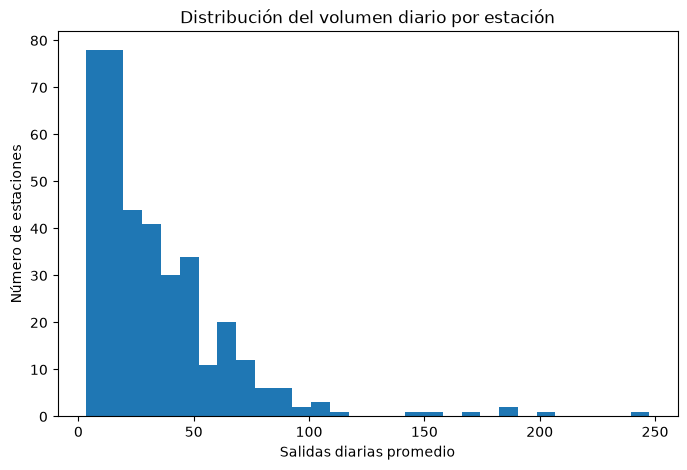

In [7]:
plt.figure(figsize=(8, 5))

plt.hist(
    perfil["volumen_diario"],
    bins=30,
)

plt.xlabel("Salidas diarias promedio")
plt.ylabel("Número de estaciones")
plt.title("Distribución del volumen diario por estación")

plt.show()

La distribución del volumen diario presenta una marcada asimetría hacia la derecha. La mayor parte de las estaciones se concentra en niveles relativamente bajos o moderados de salidas diarias, mientras que un grupo reducido alcanza volúmenes considerablemente mayores. Esta heterogeneidad es relevante para P3, ya que permite diferenciar estaciones de baja, media y alta intensidad de uso. La estadística descriptiva confirma este comportamiento: la mediana es de aproximadamente 24.54 salidas diarias, mientras que la media aumenta a 33.78 debido a las estaciones de mayor actividad y el máximo alcanza aproximadamente 247.57.

### Relación entre salidas y llegadas

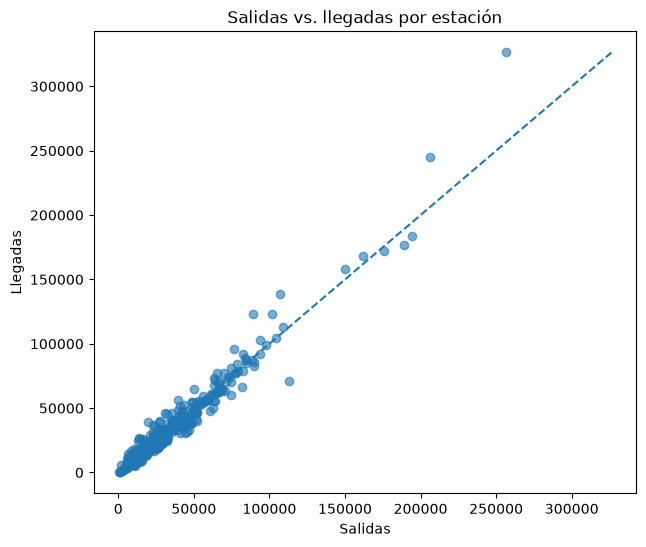

In [8]:
plt.figure(figsize=(7, 6))

plt.scatter(
    perfil["salidas"],
    perfil["llegadas"],
    alpha=0.6,
)

limite = max(
    perfil["salidas"].max(),
    perfil["llegadas"].max(),
)

plt.plot(
    [0, limite],
    [0, limite],
    linestyle="--",
)

plt.xlabel("Salidas")
plt.ylabel("Llegadas")
plt.title("Salidas vs. llegadas por estación")

plt.show()

Se observa una relación positiva marcada entre el número acumulado de salidas y llegadas de las estaciones, ya que la mayoría de los puntos se distribuye cerca de la línea diagonal de referencia. Esto indica que las estaciones con mayor actividad de salida también tienden a registrar una mayor cantidad de llegadas. Sin embargo, existen estaciones que se separan considerablemente de esta relación, indicando desequilibrios entre ambos flujos. Estas diferencias complementan el volumen total y permiten distinguir patrones operativos entre estaciones con niveles similares de actividad.

### Distribución del saldo neto

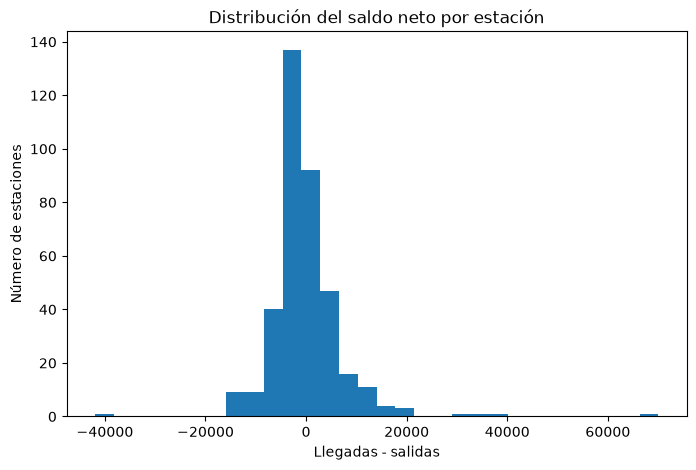

In [9]:
plt.figure(figsize=(8, 5))

plt.hist(
    perfil["saldo_neto"],
    bins=30,
)

plt.xlabel("Llegadas - salidas")
plt.ylabel("Número de estaciones")
plt.title("Distribución del saldo neto por estación")

plt.show()

El saldo neto, definido como llegadas menos salidas, se concentra principalmente alrededor de cero, aunque presenta valores extremos tanto negativos como positivos. La mediana es de -1,050 viajes, mientras que los extremos observados alcanzan -42,003 y 70,054. Un valor negativo representa una estación con más salidas que llegadas durante el periodo, mientras que uno positivo refleja el comportamiento contrario. Esta característica permite complementar las variables de volumen al distinguir la dirección predominante del flujo de bicicletas en cada estación.

### Proporción de uso durante fines de semana

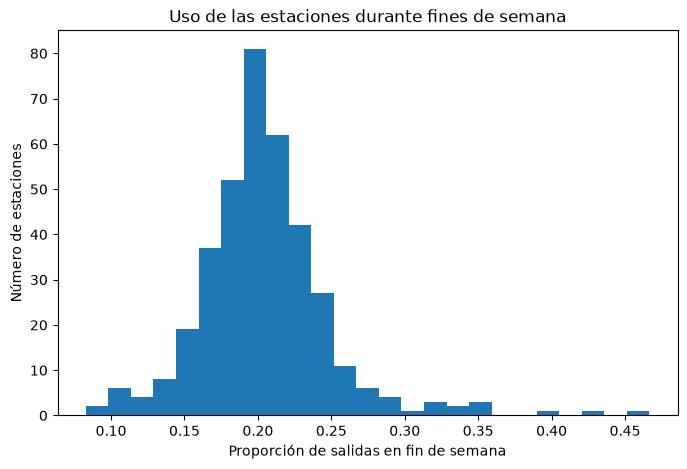

In [10]:
plt.figure(figsize=(8, 5))

plt.hist(
    perfil["proporcion_fin_semana"],
    bins=25,
)

plt.xlabel("Proporción de salidas en fin de semana")
plt.ylabel("Número de estaciones")
plt.title("Uso de las estaciones durante fines de semana")

plt.show()

La proporción de salidas durante fines de semana se concentra principalmente alrededor de 0.20, consistente con la media observada de 0.204. La mayoría de las estaciones presenta proporciones relativamente similares, aunque existen casos que superan ampliamente este nivel y alcanzan hasta aproximadamente 0.47. Esta variabilidad permite diferenciar estaciones cuyo uso se concentra principalmente durante la semana de aquellas con una participación relativamente mayor durante sábado y domingo, aportando información sobre distintos patrones temporales de utilización.

### Distribución de capacidad

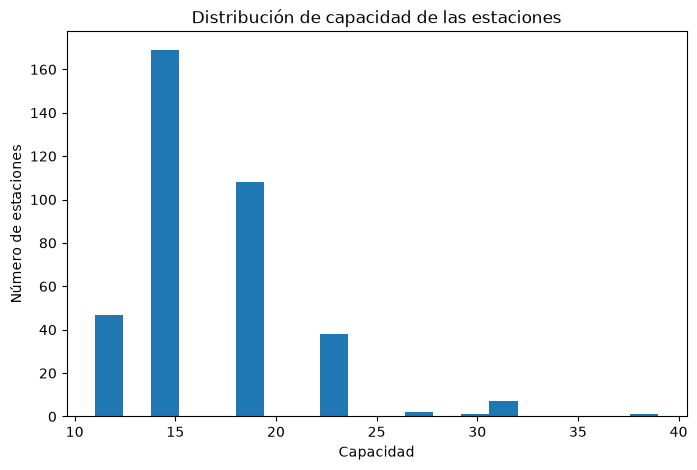

In [11]:
plt.figure(figsize=(8, 5))

plt.hist(
    perfil["capacidad"].dropna(),
    bins=20,
)

plt.xlabel("Capacidad")
plt.ylabel("Número de estaciones")
plt.title("Distribución de capacidad de las estaciones")

plt.show()

La capacidad de las estaciones se concentra en unos cuantos tamaños recurrentes, en lugar de presentar una distribución continua. Visualmente destacan especialmente las estaciones con capacidades cercanas a 15 y 19 bicicletas, mientras que las estaciones de mayor capacidad son considerablemente menos frecuentes. Incorporar esta variable al perfil P3 permite representar el tamaño operativo de cada estación y distinguir estaciones cuyo comportamiento de uso puede estar condicionado por diferencias en la infraestructura disponible.

### Perfil horario agregado

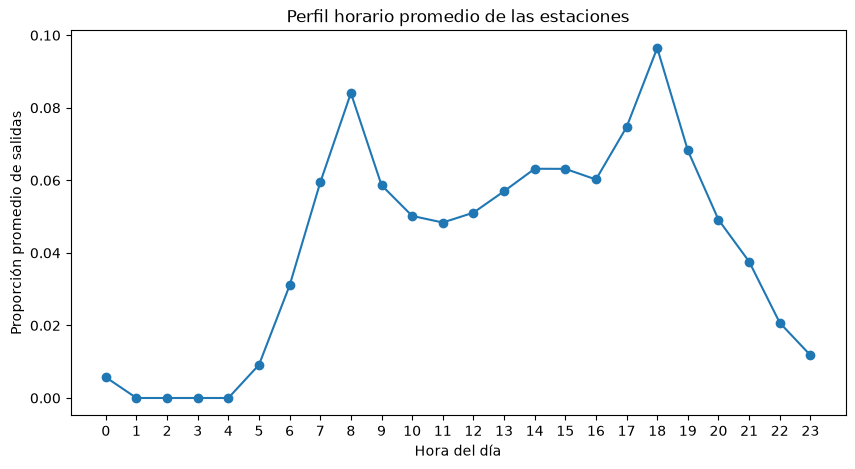

In [12]:
columnas_horas = [
    f"perfil_h{hora:02d}"
    for hora in range(24)
]

perfil_horario_promedio = (
    perfil[columnas_horas]
    .mean()
)

plt.figure(figsize=(10, 5))

plt.plot(
    range(24),
    perfil_horario_promedio.values,
    marker="o",
)

plt.xticks(range(24))
plt.xlabel("Hora del día")
plt.ylabel("Proporción promedio de salidas")
plt.title("Perfil horario promedio de las estaciones")

plt.show()

El perfil horario promedio evidencia un patrón temporal claramente estructurado. La actividad es mínima durante la madrugada, aumenta rápidamente a partir de las primeras horas de la mañana y presenta un primer máximo alrededor de las 8:00. Posteriormente disminuye y se mantiene relativamente estable durante buena parte del día, antes de presentar un segundo máximo más pronunciado alrededor de las 18:00. Después de ese punto, la proporción de salidas disminuye progresivamente durante la noche. La presencia de estos dos picos muestra que la hora de uso aporta información relevante para caracterizar el comportamiento de las estaciones y justifica la incorporación del perfil horario completo en análisis posteriores de clustering.

## 4. Baseline P3

Como referencia inicial para el problema de clustering se implementó un modelo KMeans utilizando únicamente variables de volumen: `salidas`, `llegadas` y `volumen_diario`. Las variables fueron estandarizadas antes del entrenamiento y se utilizó un número fijo de cuatro clusters.

La ejecución se realizó sobre las 373 estaciones presentes en el periodo de entrenamiento y fue registrada mediante MLflow para conservar los parámetros, métricas, versión de los datos, commit de Git y artefactos asociados.

### Resultados del baseline

El baseline KMeans con cuatro grupos obtuvo:

- **Train Silhouette Score:** 0.5985
- **Train Davies-Bouldin Index:** 0.5064

El Silhouette Score positivo indica que existe una separación apreciable entre los grupos obtenidos a partir de las variables de volumen, mientras que el índice Davies-Bouldin permite establecer una línea base cuantitativa para comparar posteriormente otras configuraciones de clustering.

Este baseline utiliza únicamente información de volumen. Por lo tanto, no incorpora todavía el perfil horario, la proporción de uso durante fines de semana, el saldo neto ni la capacidad como variables de agrupamiento. Estas características permiten explorar dimensiones adicionales del comportamiento de las estaciones que podrían utilizarse posteriormente para construir modelos de clustering más completos.

## 5. Conclusiones

La exploración muestra que las estaciones de MiBici presentan diferencias importantes tanto en intensidad como en patrones temporales de uso. El volumen diario tiene una distribución fuertemente asimétrica, mientras que las salidas y llegadas presentan una relación estrecha pero con estaciones que muestran desequilibrios relevantes. También se identifican diferencias en el uso durante fines de semana, capacidad y comportamiento horario, destacando dos periodos de mayor actividad durante el día.

Estas características justifican el planteamiento de P3 como un problema de clustering, ya que permiten representar diferentes dimensiones del comportamiento de cada estación. El baseline basado exclusivamente en volumen proporciona un primer punto de comparación reproducible, mientras que el perfil completo ofrece información adicional para analizar posteriormente agrupamientos que representen con mayor detalle la función y los patrones de uso de las estaciones.